In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, butter, sosfiltfilt, argrelextrema
from scipy.interpolate import CubicSpline
from PyEMD import EMD
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, periodogram, get_window

# Métodos

## 1. Descomposición empírica en modos (EMD, Empirical Mode Decomposition)

- Propuesto por Huang et al. (1998) en "The Empirical Mode Decomposition and the Hilbert Spectrum for Nonlinear and Non-Stationary Time Series Analysis."
- Descompone la señal en funciones de modo intrínseco (IMF, Intrinsic Mode Functions) por cribado (sifting) de la señal más rápida a las mas lentas.

### **Proceso:**
1. Identificar todos los máximos y mínimos locales de la señal.
2. Unir los máximos con un spline cúbico para formar la envolvente superior, y los mínimos para formar la envolvente inferior.
3. Calcular la media de las dos envolventes.
4. Restar esa media a la señal.
5. Repetir los pasos 1 a 4 sobre el resultado hasta que cumpla las dos condiciones de una IMF. Esa es la primera IMF.
6. Restar la IMF a la señal original y repetir todo el proceso con lo que queda para extraer la siguiente IMF.

### **Condiciones de una IMF:**
1. La suma de los maximos y minimos menos los cruces por cero es igual o menor que uno.
2. Media local igual a cero en cada instante.

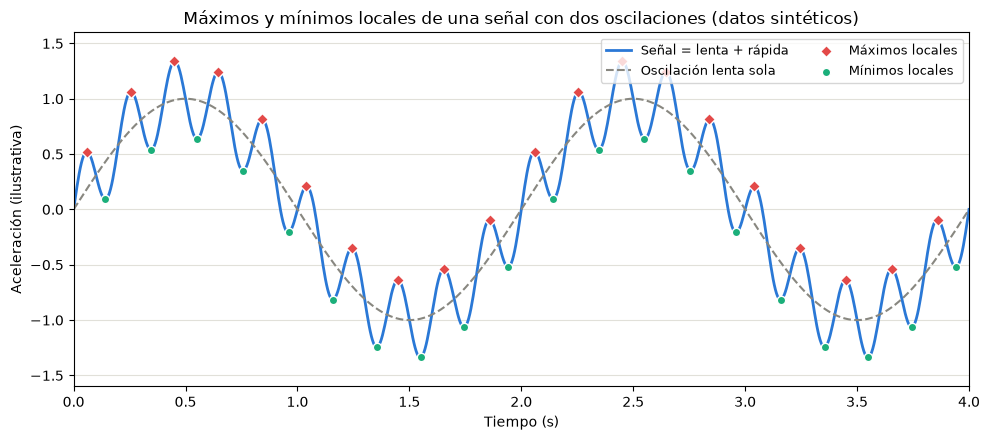

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros de la señal
fs = 200          # frecuencia de muestreo (Hz)
duration = 4.0    # duración de la señal (s)
a_slow, f_slow = 1.0, 0.5    # oscilación lenta: amplitud, frecuencia (Hz)
a_fast, f_fast = 0.35, 5.0   # oscilación rápida: amplitud, frecuencia (Hz)

# Vector de tiempo muestreado y señal
t = np.arange(0, duration + 1 / fs, 1 / fs)
x_slow = a_slow * np.sin(2 * np.pi * f_slow * t)
x_fast = a_fast * np.sin(2 * np.pi * f_fast * t)
x = x_slow + x_fast

# Extremos locales: comparar cada muestra con sus vecinas
is_max = (x[1:-1] > x[:-2]) & (x[1:-1] >= x[2:])
is_min = (x[1:-1] < x[:-2]) & (x[1:-1] <= x[2:])
idx_max = np.where(is_max)[0] + 1
idx_min = np.where(is_min)[0] + 1

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(t, x, color="#2a78d6", lw=2, label="Señal = lenta + rápida")
ax.plot(t, x_slow, color="#888780", lw=1.5, ls="--", label="Oscilación lenta sola")
ax.scatter(t[idx_max], x[idx_max], marker="D", s=36, color="#e34948",
           edgecolor="white", zorder=3, label="Máximos locales")
ax.scatter(t[idx_min], x[idx_min], marker="o", s=36, color="#1baf7a",
           edgecolor="white", zorder=3, label="Mínimos locales")

ax.set_title("Máximos y mínimos locales de una señal con dos oscilaciones (datos sintéticos)")
ax.set_xlabel("Tiempo (s)")
ax.set_ylabel("Aceleración (ilustrativa)")
ax.set_xlim(0, duration)
ax.set_ylim(-1.6, 1.6)
ax.grid(axis="y", color="#e1e0d9")
ax.legend(loc="upper right", fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

Hay un máximo y un mínimo por cada ciclo de la oscilación rápida. La oscilación lenta no crea picos propios: solo sube y baja la altura a la que caen los picos de la rápida.

En Python se puede usas la librería `PyEMD` para aplicar el método y descomponer una señal en sus IMFs.

### **Limitantes:**
- Mezcla de modos: cuando dos oscilaciones vibran a frecuencias cercanas, el EMD puede mezclar ambas en una sola IMF.
- Modos repartidos en diferentes IMFs: cuando una oscilacion es intermietente, puede provocar que 1 modo de vibracion se reparta en dos IMFs.
- Malekjafarian et. al (2017) demostraron que si la excitación hace entrar en resonancia el modo que se busca, ese modo domina la señal y la EMD lo separa fácilmente en una IMF.

### **Ejemplo:**

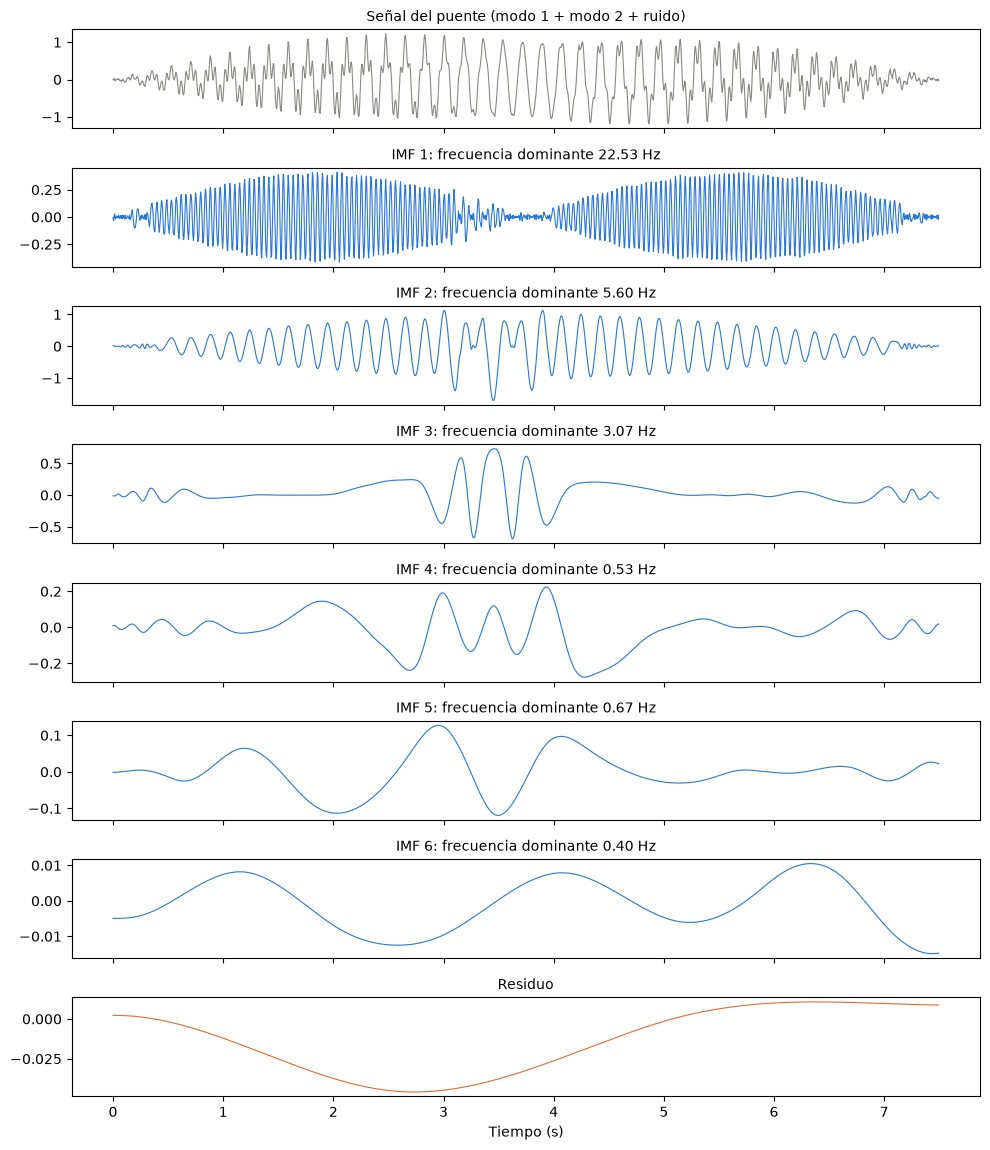

In [3]:
# Colores (mismos roles que en metodos.ipynb)
COLOR_SIGNAL = "#8a8984"   # señal medida (gris neutro)
COLOR_1 = "#2a78d6"        # serie principal (azul)
COLOR_2 = "#eb6834"        # segunda serie (naranja)

# Ejemplo común: vehículo que cruza un puente simplemente apoyado
L_SPAN = 15.0         # luz (m)
V_SPEED = 2.0         # velocidad del vehículo (m/s)
F1, F2 = 5.65, 22.62  # frecuencias naturales del puente (Hz)
FS = 200.0            # frecuencia de muestreo (Hz)

t = np.arange(0, L_SPAN / V_SPEED, 1 / FS)
position = V_SPEED * t                         # posición del vehículo x = v t (m)
phi_1 = np.sin(np.pi * position / L_SPAN)      # forma del modo 1
phi_2 = np.sin(2 * np.pi * position / L_SPAN)  # forma del modo 2

rng = np.random.default_rng(42)   # semilla fija para el ruido

# Señal del puente: modo 1 + modo 2 + ruido pequeño
x_bridge = (phi_1 * np.cos(2 * np.pi * F1 * t)
            + 0.4 * phi_2 * np.cos(2 * np.pi * F2 * t)
            + 0.02 * rng.standard_normal(t.size))


def dominant_frequency(x, fs):
    # Frecuencia del pico más alto de la FFT (sin contar 0 Hz)
    spectrum = np.abs(np.fft.rfft(x - x.mean()))
    freqs = np.fft.rfftfreq(x.size, 1 / fs)
    return freqs[np.argmax(spectrum[1:]) + 1]


emd = EMD()
emd.emd(x_bridge, t)
imfs, residue = emd.get_imfs_and_residue()

n_rows = imfs.shape[0] + 2
fig, axes = plt.subplots(n_rows, 1, figsize=(10, 1.45 * n_rows), sharex=True)
axes[0].plot(t, x_bridge, color=COLOR_SIGNAL, linewidth=0.8)
axes[0].set_title("Señal del puente (modo 1 + modo 2 + ruido)", fontsize=10)
for i, imf in enumerate(imfs):
    axes[i + 1].plot(t, imf, color=COLOR_1, linewidth=0.8)
    axes[i + 1].set_title(f"IMF {i + 1}: frecuencia dominante {dominant_frequency(imf, FS):.2f} Hz",
                          fontsize=10)
axes[-1].plot(t, residue, color=COLOR_2, linewidth=0.8)
axes[-1].set_title("Residuo", fontsize=10)
axes[-1].set_xlabel("Tiempo (s)")
fig.tight_layout()
plt.show()

<div style="break-before: page; page-break-before: always;"></div>

## 2. PSD a partir de la autocorrelación y la transformada de Fourier

- Basado en el teorema de Wiener-Khinchin (Wiener, 1930; Khinchin, 1934): la PSD es la transformada de Fourier de la autocorrelación.
- Visto en CIV E 789: autocorrelación en la sesión 5 (clase 3, diapositivas 20 a 23) y la PSD como transformada de la autocorrelación en la sesión 7 (clase 4, diapositiva 22).
- La autocorrelación mide cuánto se parece la señal a sí misma desplazada un tiempo $\tau$. Al pasarla al dominio de la frecuencia con la transformada de Fourier, se obtiene la PSD.

$$S_{xx}(f) = \int_{-\infty}^{\infty} R_{xx}(\tau)\, e^{-j2\pi f\tau}\, d\tau$$

- $S_{xx}(f)$: PSD de la señal $x$ en la frecuencia $f$.
- $R_{xx}(\tau)$: autocorrelación de $x$ para un desfase $\tau$.
- $e^{-j2\pi f\tau}$: la transformada de Fourier, que compara la autocorrelación con una oscilación de frecuencia $f$.

### **Proceso:**
1. Quitar la media de la señal.
2. Calcular la autocorrelación para todos los desfases.
3. Calcular la transformada de Fourier de la autocorrelación.

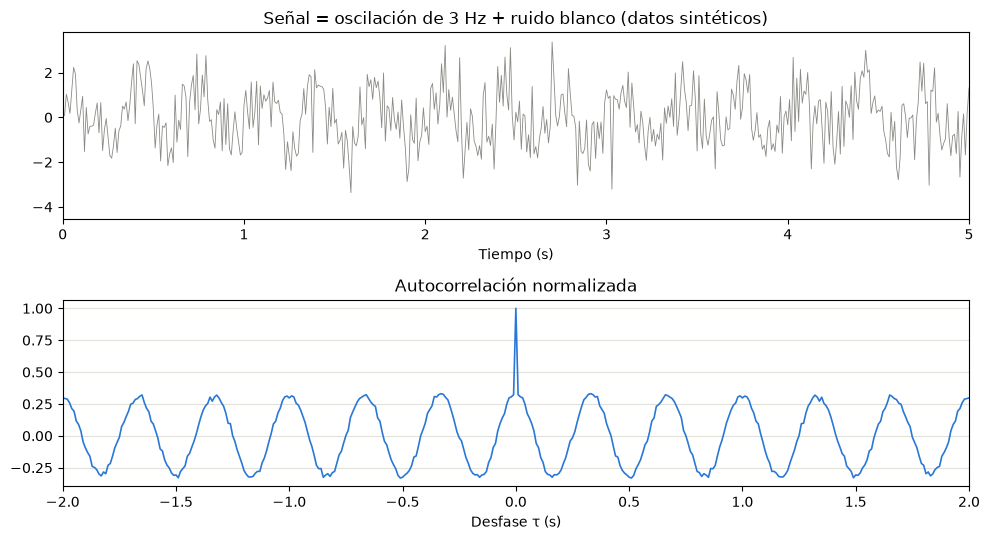

In [4]:
fs = 100.0         # frecuencia de muestreo (Hz)
duration = 20.0    # duración de la señal (s)
f0 = 3.0           # frecuencia del tono (Hz)

rng = np.random.default_rng(0)
t = np.arange(0, duration, 1 / fs)
x = np.sin(2 * np.pi * f0 * t) + 1.0 * rng.standard_normal(t.size)
x = x - x.mean()

# Autocorrelación sesgada (dividida entre N), normalizada para que R(0) = 1
r = np.correlate(x, x, mode="full") / x.size
lags = np.arange(-x.size + 1, x.size) / fs
r = r / r[x.size - 1]

fig, (ax_sig, ax_r) = plt.subplots(2, 1, figsize=(10, 5.5))
ax_sig.plot(t, x, color="#8a8984", lw=0.6)
ax_sig.set_title("Señal = oscilación de 3 Hz + ruido blanco (datos sintéticos)")
ax_sig.set_xlabel("Tiempo (s)")
ax_sig.set_xlim(0, 5)
ax_r.plot(lags, r, color="#2a78d6", lw=1.2)
ax_r.set_title("Autocorrelación normalizada")
ax_r.set_xlabel("Desfase τ (s)")
ax_r.set_xlim(-2, 2)
ax_r.grid(axis="y", color="#e1e0d9")
plt.tight_layout()
plt.show()

En la señal casi no se ve la oscilación, pero en la autocorrelación sí: el ruido blanco solo aporta un pico en $\tau = 0$, mientras que la oscilación de 3 Hz deja un coseno que se repite cada 0.33 s. Su transformada de Fourier da un pico en 3 Hz.

En Python, la autocorrelación se calcula con `np.correlate(x, x, mode="full")` o `scipy.signal.correlate`, y la transformada con `np.fft.fft`.

### **Usos principales:**
- Obtener la PSD y, con ella, las frecuencias naturales (los picos).
- Con la correlación cruzada entre sensores se obtienen las PSD cruzadas que usa la FDD.
- Es la base de métodos de identificación con vibración ambiental que trabajan con correlaciones, como NExT.

### **Limitantes:**
- El resultado es exactamente el periodograma ($|FFT|^2$ de toda la señal), así que fluctúa igual.
- Los desfases grandes se calculan con pocas muestras y son poco confiables.

### **Ejemplo:**

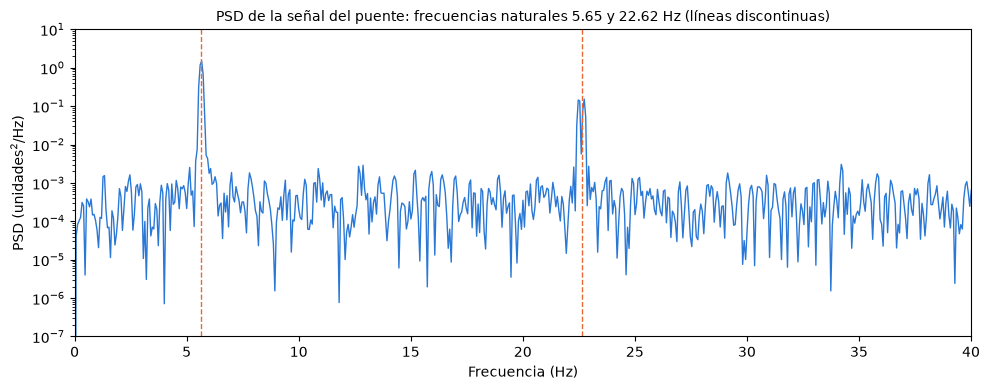

In [5]:
# Colores (mismos roles que en metodos.ipynb)
COLOR_SIGNAL = "#8a8984"   # señal medida (gris neutro)
COLOR_1 = "#2a78d6"        # serie principal (azul)
COLOR_2 = "#eb6834"        # segunda serie (naranja)

# Ejemplo común: vehículo que cruza un puente simplemente apoyado
L_SPAN = 15.0         # luz (m)
V_SPEED = 2.0         # velocidad del vehículo (m/s)
F1, F2 = 5.65, 22.62  # frecuencias naturales del puente (Hz)
FS = 200.0            # frecuencia de muestreo (Hz)

t = np.arange(0, L_SPAN / V_SPEED, 1 / FS)
position = V_SPEED * t                         # posición del vehículo x = v t (m)
phi_1 = np.sin(np.pi * position / L_SPAN)      # forma del modo 1
phi_2 = np.sin(2 * np.pi * position / L_SPAN)  # forma del modo 2

rng = np.random.default_rng(42)   # semilla fija para el ruido

# Señal del puente: modo 1 + modo 2 + ruido
x_bridge = (phi_1 * np.cos(2 * np.pi * F1 * t)
            + 0.4 * phi_2 * np.cos(2 * np.pi * F2 * t)
            + 0.2 * rng.standard_normal(t.size))
x_bridge = x_bridge - x_bridge.mean()
N = x_bridge.size


def psd_from_autocorr(r_full, fs, n_fft):
    # PSD de un lado = transformada de Fourier de la autocorrelación (desfases -(N-1)...(N-1))
    r_circ = np.fft.ifftshift(r_full)              # poner el desfase 0 primero
    s = np.real(np.fft.fft(r_circ, n_fft)) / fs    # PSD de dos lados (unidades^2/Hz)
    f = np.fft.rfftfreq(n_fft, 1 / fs)
    s_one = s[:f.size].copy()
    last = -1 if n_fft % 2 == 0 else None          # el bin de Nyquist solo existe si n_fft es par
    s_one[1:last] *= 2                             # un lado: duplicar todos los bins excepto 0 Hz y Nyquist
    return f, s_one


r_full = np.correlate(x_bridge, x_bridge, mode="full") / N   # autocorrelación sesgada
n_fft = 2 * N - 1

# PSD = transformada de Fourier de la autocorrelación
f_ac, s_ac = psd_from_autocorr(r_full, FS, n_fft)

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(f_ac, s_ac, color=COLOR_1, lw=1)
for f_n in (F1, F2):
    ax.axvline(f_n, color=COLOR_2, ls="--", lw=1)
ax.set_title("PSD de la señal del puente: frecuencias naturales 5.65 y 22.62 Hz (líneas discontinuas)", fontsize=10)
ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("PSD (unidades$^2$/Hz)")
ax.set_xlim(0, 40)
ax.set_ylim(1e-7, 10)
fig.tight_layout()
plt.show()

Los picos de la PSD aparecen en las frecuencias naturales del puente (5.65 y 22.62 Hz). El piso entre los picos corresponde al ruido.

<div style="break-before: page; page-break-before: always;"></div>

## 3. Densidad espectral de potencia (PSD, Power Spectral Density): método de Welch

- Propuesto por Welch (1967) en "The Use of Fast Fourier Transform for the Estimation of Power Spectra: A Method Based on Time Averaging Over Short, Modified Periodograms."
- Estima cómo se reparte la energía de la señal entre las frecuencias. En vez de una sola FFT de toda la señal, promedia las FFT de varios segmentos para obtener un espectro más estable.

### **Proceso:**
1. Dividir la señal en segmentos con 50 % de solape.
2. Multiplicar cada segmento por una ventana Hann.
3. Calcular la FFT de cada segmento y su potencia $|X|^2$.
4. Promediar las potencias de todos los segmentos.

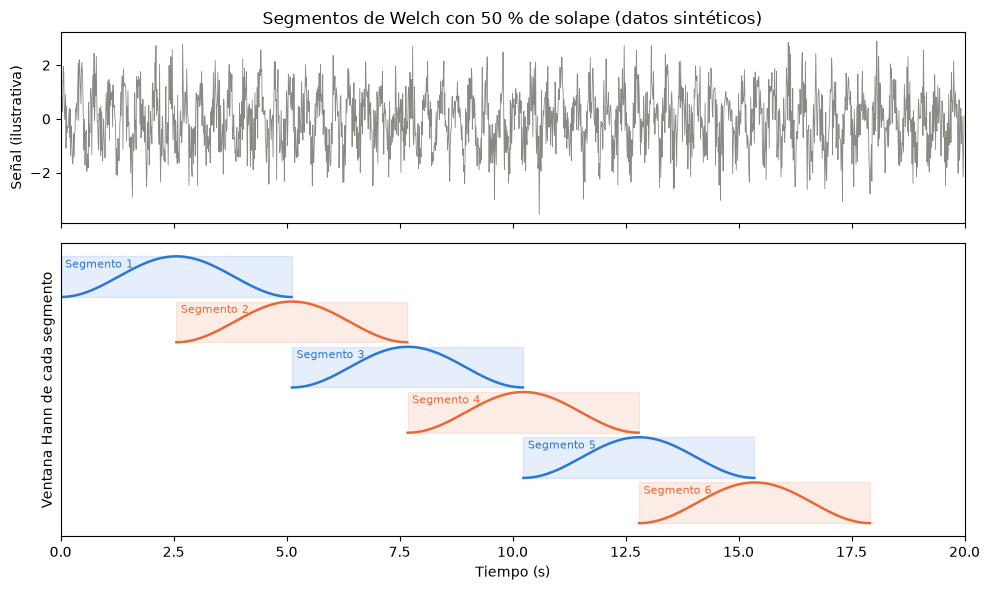

In [6]:
fs = 100.0            # frecuencia de muestreo (Hz)
duration = 20.0       # duración de la señal (s)
n_seg = 512           # muestras por segmento
step = n_seg // 2     # 50 % de solape

rng = np.random.default_rng(0)
t = np.arange(0, duration, 1 / fs)
x = np.sin(2 * np.pi * 3.0 * t) + 0.8 * rng.standard_normal(t.size)

starts = np.arange(0, t.size - n_seg + 1, step)
hann = get_window("hann", n_seg)

fig, (ax_sig, ax_win) = plt.subplots(2, 1, figsize=(10, 6), sharex=True,
                                     gridspec_kw={"height_ratios": [1.3, 2]})
ax_sig.plot(t, x, color="#8a8984", lw=0.6)
ax_sig.set_title("Segmentos de Welch con 50 % de solape (datos sintéticos)")
ax_sig.set_ylabel("Señal (ilustrativa)")

# Una fila por segmento: franja sombreada = muestras usadas, curva = ventana Hann aplicada a ellas
for i, s in enumerate(starts):
    row = starts.size - 1 - i
    color = ["#2a78d6", "#eb6834"][i % 2]
    seg_t = t[s:s + n_seg]
    ax_win.axhspan(row, row + 0.9, xmin=seg_t[0] / duration, xmax=seg_t[-1] / duration,
                   color=color, alpha=0.12)
    ax_win.plot(seg_t, row + 0.9 * hann, color=color, lw=1.8)
    ax_win.text(seg_t[0] + 0.1, row + 0.65, f"Segmento {i + 1}", fontsize=8, color=color)
ax_win.set_yticks([])
ax_win.set_ylabel("Ventana Hann de cada segmento")
ax_win.set_xlabel("Tiempo (s)")
ax_win.set_xlim(0, duration)
plt.tight_layout()
plt.show()

Cada fila es un segmento: la franja muestra las muestras que usa y la curva, la ventana Hann que se les aplica. Cada segmento empieza en la mitad del anterior (50 % de solape), así que cada instante entra en dos segmentos, y la ventana hace que los bordes de cada segmento pesen poco.

En Python se puede usar `scipy.signal.welch` para calcular la PSD.

### **Usos principales:**
- Identificar las frecuencias naturales de la estructura (los picos), sobre todo con vibración ambiental.
- Estimar el amortiguamiento a partir del ancho de los picos (método de media potencia, half-power bandwidth).
- Calcular PSD cruzadas entre sensores para obtener las formas modales (FDD), la FRF y la coherencia.
- Monitorear cambios en las frecuencias o en la energía de cada modo como indicador de daño.

### **Limitantes:**
- Compromiso entre resolución y estabilidad: segmentos más cortos dan más promedios y un espectro más suave, pero los picos se ensanchan ($\Delta f = f_s/N_{seg}$).
- Supone una señal estacionaria: si el contenido cambia en el tiempo, pierde cuándo ocurrió (para eso están el STFT y las wavelets).
- Promediar reduce la fluctuación de la estimación, no el ruido de la señal.

### **Welch vs. FFT de toda la señal:**
| | FFT de toda la señal | PSD con Welch |
|---|---|---|
| Resolución en frecuencia | Mejor (separa picos cercanos) | Menor ($\Delta f = f_s/N_{seg}$) |
| Estabilidad del espectro | Fluctúa mucho y no mejora con registros más largos | Más estable al promediar segmentos |
| Picos falsos por ruido | Frecuentes | Menos, los picos reales se distinguen mejor |
| Depende de la duración del registro | Sí (la magnitud cambia con el número de muestras) | No (se normaliza por hertz) |
| Coherencia y PSD cruzadas | Sin sentido (con un solo bloque la coherencia da 1) | Confiables |

### **Ejemplo:**

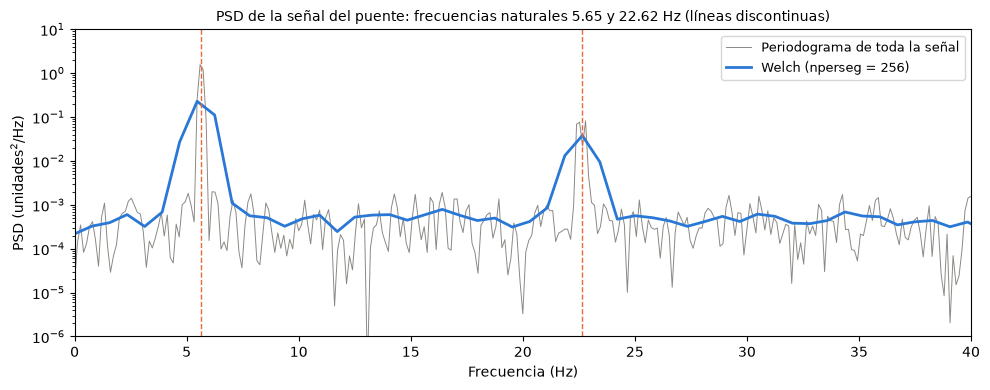

In [7]:
# Colores (mismos roles que en metodos.ipynb)
COLOR_SIGNAL = "#8a8984"   # señal medida (gris neutro)
COLOR_1 = "#2a78d6"        # serie principal (azul)
COLOR_2 = "#eb6834"        # segunda serie (naranja)

# Ejemplo común: vehículo que cruza un puente simplemente apoyado
L_SPAN = 15.0         # luz (m)
V_SPEED = 2.0         # velocidad del vehículo (m/s)
F1, F2 = 5.65, 22.62  # frecuencias naturales del puente (Hz)
FS = 200.0            # frecuencia de muestreo (Hz)

t = np.arange(0, L_SPAN / V_SPEED, 1 / FS)
position = V_SPEED * t                         # posición del vehículo x = v t (m)
phi_1 = np.sin(np.pi * position / L_SPAN)      # forma del modo 1
phi_2 = np.sin(2 * np.pi * position / L_SPAN)  # forma del modo 2

rng = np.random.default_rng(42)   # semilla fija para el ruido

# Señal del puente: modo 1 + modo 2 + ruido
x_bridge = (phi_1 * np.cos(2 * np.pi * F1 * t)
            + 0.4 * phi_2 * np.cos(2 * np.pi * F2 * t)
            + 0.2 * rng.standard_normal(t.size))

f_per, p_per = periodogram(x_bridge, FS, window="hann")        # una sola FFT de todo el registro
f_w, p_w = welch(x_bridge, FS, window="hann", nperseg=256)     # promedio de Welch

fig, ax = plt.subplots(figsize=(10, 4))
ax.semilogy(f_per, p_per, color=COLOR_SIGNAL, lw=0.7, label="Periodograma de toda la señal")
ax.semilogy(f_w, p_w, color=COLOR_1, lw=2, label="Welch (nperseg = 256)")
for f_n in (F1, F2):
    ax.axvline(f_n, color=COLOR_2, ls="--", lw=1)
ax.set_title("PSD de la señal del puente: frecuencias naturales 5.65 y 22.62 Hz (líneas discontinuas)", fontsize=10)
ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("PSD (unidades$^2$/Hz)")
ax.set_xlim(0, 40)
ax.set_ylim(1e-6, 10)
ax.legend(loc="upper right", fontsize=9)
fig.tight_layout()
plt.show()

El periodograma de toda la señal tiene picos más angostos, pero su piso de ruido fluctúa mucho. Welch da un espectro más estable, a cambio de picos más anchos.

<div style="break-before: page; page-break-before: always;"></div>

## 4. Descomposición en valores singulares (SVD, Singular Value Decomposition)

- Desarrollada por Beltrami (1873) y Jordan (1874).
- Visto en CIV E 789, sesión 8 (22 oct 2026), como la base de la FDD (clase 4, diapositiva 29).
- Descompone cualquier matriz $A$ (de $m \times n$) en el producto de tres matrices:

$$A = U\,\Sigma\,V^T$$

**$U$ ($m \times m$): direcciones de los ejes.** Sus columnas $\mathbf{u}_i$ son las direcciones principales de los datos, perpendiculares entre sí.

$$U = \begin{bmatrix} | & | & & | \\ \mathbf{u}_1 & \mathbf{u}_2 & \cdots & \mathbf{u}_m \\ | & | & & | \end{bmatrix}$$

**$\Sigma$ ($m \times n$): longitud de los ejes.** Es diagonal; los valores singulares $\sigma_i$ dicen cuánto pesa cada dirección y van de mayor a menor.

$$\Sigma = \begin{bmatrix} \sigma_1 & 0 & \cdots & 0 \\ 0 & \sigma_2 & \cdots & 0 \\ \vdots & \vdots & \ddots & \vdots \\ 0 & 0 & \cdots & \sigma_r \end{bmatrix}, \qquad \sigma_1 \geq \sigma_2 \geq \dots \geq \sigma_r \geq 0$$

**$V^T$ ($n \times n$): cómo se combinan.** Sus filas $\mathbf{v}_i^T$ dicen cómo se combina cada dirección para reconstruir los datos.

$$V^T = \begin{bmatrix} \text{---} & \mathbf{v}_1^T & \text{---} \\ \text{---} & \mathbf{v}_2^T & \text{---} \\ & \vdots & \\ \text{---} & \mathbf{v}_n^T & \text{---} \end{bmatrix}$$

- $r$: el número de valores singulares distintos de cero (el rango de $A$).

En Python se usa `np.linalg.svd(A)`.

### **En dinámica estructural:**
Si se aplica a la matriz de desplazamientos $X$, con una fila por sensor ($m$ sensores) y una columna por instante de tiempo ($N$ instantes):

$$X = \begin{bmatrix} x_1(t_1) & x_1(t_2) & \cdots & x_1(t_N) \\ x_2(t_1) & x_2(t_2) & \cdots & x_2(t_N) \\ \vdots & \vdots & \ddots & \vdots \\ x_m(t_1) & x_m(t_2) & \cdots & x_m(t_N) \end{bmatrix}$$

- $x_j(t_k)$: desplazamiento del sensor $j$ en el instante $t_k$.

**$U$: las formas modales.** Cada columna $\boldsymbol{\phi}_i$ dice cuánto se mueve cada sensor en el modo $i$.

$$U = \begin{bmatrix} | & | & & | \\ \boldsymbol{\phi}_1 & \boldsymbol{\phi}_2 & \cdots & \boldsymbol{\phi}_r \\ | & | & & | \end{bmatrix} = \begin{bmatrix} \phi_{11} & \phi_{12} & \cdots & \phi_{1r} \\ \phi_{21} & \phi_{22} & \cdots & \phi_{2r} \\ \vdots & \vdots & \ddots & \vdots \\ \phi_{m1} & \phi_{m2} & \cdots & \phi_{mr} \end{bmatrix}$$

- $\phi_{ji}$: amplitud del sensor $j$ en el modo $i$.

**$\Sigma$: la energía de cada modo.** Cada $\sigma_i$ dice con cuánta amplitud vibra el modo $i$; el que más vibra queda primero.

$$\Sigma = \begin{bmatrix} \sigma_1 & & \\ & \ddots & \\ & & \sigma_r \end{bmatrix}$$

**$V^T$: la historia temporal de cada modo.** Cada fila es cómo varía el modo $i$ en el tiempo (normalizada).

$$V^T = \begin{bmatrix} q_1(t_1) & q_1(t_2) & \cdots & q_1(t_N) \\ q_2(t_1) & q_2(t_2) & \cdots & q_2(t_N) \\ \vdots & \vdots & \ddots & \vdots \\ q_r(t_1) & q_r(t_2) & \cdots & q_r(t_N) \end{bmatrix}$$

- $q_i(t_k)$: valor de la coordenada del modo $i$ en el instante $t_k$.

Al multiplicar las tres, la respuesta queda como la suma de los modos:

$$X = \sum_{i=1}^{r} \sigma_i\, \boldsymbol{\phi}_i\, \mathbf{q}_i^T$$

Esto funciona porque la respuesta de una estructura es justamente una suma de modos, y la SVD los separa a partir de la respuesta medida, sin conocer la matriz de rigidez. La FDD usa la misma idea, pero aplicada a la matriz de PSD de los sensores en cada frecuencia.

### **Limitantes:**
- Los vectores singulares siempre son perpendiculares; las formas modales solo lo son respecto a la masa. Si la masa no es uniforme o hay modos muy cercanos, no coinciden exactamente.
- En una matriz de respuestas, la SVD ordena por energía, no por modo: si dos modos vibran con energía parecida, se pueden mezclar.

<div style="break-before: page; page-break-before: always;"></div>

## 5. Descomposición en el dominio de la frecuencia (FDD, Frequency Domain Decomposition)

- Propuesto por Brincker, Zhang y Andersen (2001) en "Modal identification of output-only systems using frequency domain decomposition" (*Smart Materials and Structures*, 10(3), 441–445).
- Visto en CIV E 789, sesión 8 (22 oct 2026), clase 4, diapositivas 29 a 31.
- Identifica las frecuencias naturales y las formas modales usando solo la respuesta medida por varios sensores (vibración ambiental), sin conocer la excitación. Supone que la excitación es como ruido blanco.

### **Proceso:**
1. Calcular la matriz de PSD de todos los sensores en cada frecuencia (auto-PSD en la diagonal, PSD cruzada fuera de la diagonal).
2. Aplicar la SVD a la matriz de PSD en cada frecuencia.
3. Graficar el primer valor singular contra la frecuencia: sus picos son las frecuencias naturales.
4. En cada pico, el primer vector singular es la forma modal.

### **Matrices:**
Con $m$ sensores, en cada frecuencia $f$ se arma la matriz de PSD:

$$G(f) = \begin{bmatrix} G_{11}(f) & G_{12}(f) & \cdots & G_{1m}(f) \\ G_{21}(f) & G_{22}(f) & \cdots & G_{2m}(f) \\ \vdots & \vdots & \ddots & \vdots \\ G_{m1}(f) & G_{m2}(f) & \cdots & G_{mm}(f) \end{bmatrix}$$

- $G_{jj}(f)$: PSD del sensor $j$ (diagonal).
- $G_{jk}(f)$: PSD cruzada entre los sensores $j$ y $k$ (fuera de la diagonal).

Y se descompone con la SVD:

$$G(f) = U(f)\, S(f)\, U(f)^H$$

- $U(f)$: sus columnas son los vectores singulares; cerca de una frecuencia natural, la primera columna es la forma modal.

$$U(f) = \begin{bmatrix} | & | & & | \\ \mathbf{u}_1(f) & \mathbf{u}_2(f) & \cdots & \mathbf{u}_m(f) \\ | & | & & | \end{bmatrix}$$

- $S(f)$: matriz diagonal con los valores singulares $s_1(f) \geq s_2(f) \geq \dots$; cada uno es la energía de un modo en esa frecuencia.

$$S(f) = \begin{bmatrix} s_1(f) & & \\ & \ddots & \\ & & s_m(f) \end{bmatrix}$$

- $U(f)^H$: la transpuesta conjugada de $U(f)$ (porque las PSD cruzadas son números complejos). Como $G(f)$ es hermítica, la misma $U$ aparece a los dos lados.

Cerca de la frecuencia natural $f_i$ domina un solo modo, así que:

$$G(f_i) \approx s_1(f_i)\, \boldsymbol{\phi}_i\, \boldsymbol{\phi}_i^H$$

- $\boldsymbol{\phi}_i$: la forma modal del modo $i$, igual al primer vector singular $\mathbf{u}_1(f_i)$.

En Python, la matriz de PSD se calcula con `scipy.signal.csd` para cada par de sensores, y la SVD con `np.linalg.svd`.

### **Usos principales:**
- Identificación modal con vibración ambiental (tráfico, viento) en puentes y edificios, sin cerrar la estructura ni medir la carga.
- Obtener las formas modales para calcular el MAC y compararlas entre estados (intacto y dañado).
- Separar modos con frecuencias cercanas, que con la selección de picos (peak picking) se mezclan.

### **Limitantes:**
- Supone excitación de ruido blanco: un armónico (por ejemplo, un motor) aparece como un pico que no es un modo.
- No da el amortiguamiento (para eso está la EFDD).
- La resolución depende de la PSD: modos muy cercanos o muy amortiguados son difíciles de separar.
- Supone que la estructura no cambia durante la medición.